### Persiapan Data

In [1]:
# import package
import numpy as np
import pandas as pd

In [2]:
# Baca dataset dari folder notebook atau dari root proyek.
from pathlib import Path

dataset_path = Path('burnout_dataset1.csv')
if not dataset_path.is_file():
    dataset_path = Path('Pertemuan_7') / 'Dataset PBL' / 'burnout_dataset1.csv'

data = pd.read_csv(dataset_path)
# Imputasi nilai kosong pada kolom numerik dengan rata-rata
num_cols = data.select_dtypes(include=[np.number]).columns
data[num_cols] = data[num_cols].fillna(data[num_cols].mean())
data.head()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.000000,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.000000,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.000000,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.000000,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,6251.281524,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


In [3]:
# Pemahaman terhadap data
print('Ukuran data (baris, kolom):', data.shape)
data.info()
data.describe()

Ukuran data (baris, kolom): (50000, 40)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Person_ID                      50000 non-null  int64  
 1   Age                            50000 non-null  float64
 2   Gender                         50000 non-null  str    
 3   Country                        50000 non-null  str    
 4   Occupation                     50000 non-null  str    
 5   Education_Level                50000 non-null  str    
 6   Employment_Status              50000 non-null  str    
 7   Monthly_Income_USD             50000 non-null  float64
 8   Work_Hours_Per_Week            50000 non-null  int64  
 9   Remote_Work                    50000 non-null  str    
 10  Job_Satisfaction               50000 non-null  float64
 11  Work_Life_Balance              50000 non-null  float64
 12  Sleep_Hours      

,Person_ID,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,...,Physical_Activity_Hours,Meditation_Minutes,Screen_Time_Hours,Social_Media_Hours,Gaming_Hours,Coffee_Cups_Per_Day,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000
mean,25000.500000,41.448181,6251.281524,44.946160,5.499051,5.504397,6.997445,40.449045,40.601160,59.622994,...,4.988035,30.028955,7.991274,3.991674,2.988227,3.991440,5.521298,59.444179,14.970220,40.20188
std,14433.901067,13.836911,3271.171234,14.729024,2.852252,2.848792,1.712264,25.795413,26.084344,25.550377,...,2.838268,17.394566,3.442855,2.291547,1.715532,2.581221,2.848364,25.780300,8.965856,26.22312
min,1.000000,18.000000,500.000000,20.000000,1.000000,1.000000,4.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000
25%,12500.750000,29.000000,3470.750000,32.000000,3.000000,3.000000,5.500000,20.000000,20.000000,42.000000,...,2.600000,15.000000,5.000000,2.000000,1.500000,2.000000,3.000000,41.000000,7.000000,19.00000
50%,25000.500000,41.448181,6251.281524,45.000000,5.499051,5.504397,7.000000,40.000000,40.000000,60.000000,...,4.988035,30.028955,7.991274,3.991674,2.988227,4.000000,5.521298,60.000000,15.000000,39.00000
75%,37500.250000,53.000000,9045.250000,58.000000,8.000000,8.000000,8.500000,59.000000,59.000000,80.000000,...,7.400000,45.000000,11.000000,6.000000,4.500000,6.000000,8.000000,80.000000,23.000000,59.00000
max,50000.000000,65.000000,12000.000000,70.000000,10.000000,10.000000,10.000000,100.000000,100.000000,100.000000,...,10.000000,60.000000,14.000000,8.000000,6.000000,8.000000,10.000000,100.000000,30.000000,100.00000


### Visualisasi Data

In [4]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

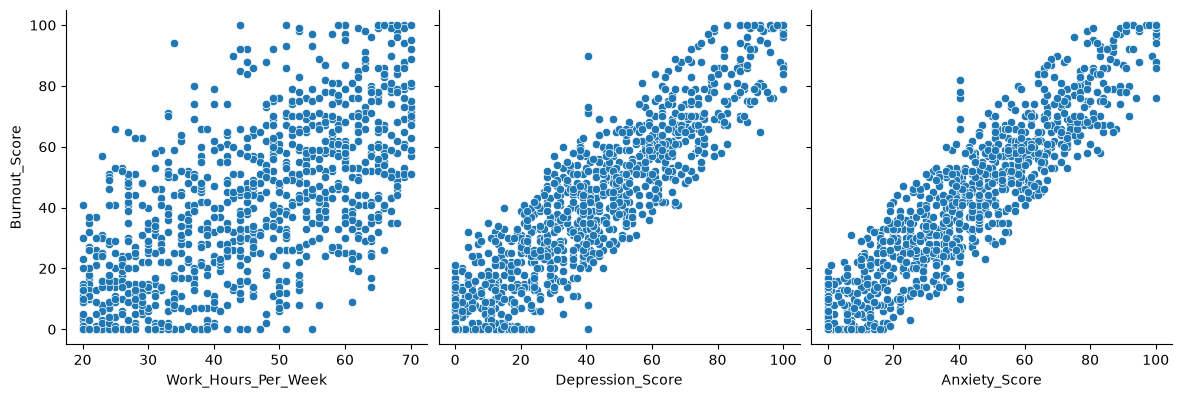

In [5]:
# Hubungan variabel bebas dengan variabel target (gunakan sampel agar plot terbaca jelas)
data_sample = data.sample(n=1000, random_state=42)
sns.pairplot(
    data_sample,
    x_vars=['Work_Hours_Per_Week', 'Depression_Score', 'Anxiety_Score'],
    y_vars='Burnout_Score',
    height=4, aspect=1, kind='scatter'
)
plt.show()

Scatter plot menunjukkan hubungan masing-masing variabel bebas dengan target Burnout_Score. Heatmap berikut menghitung korelasi pada kolom numerik utama agar anotasi tetap mudah dibaca.

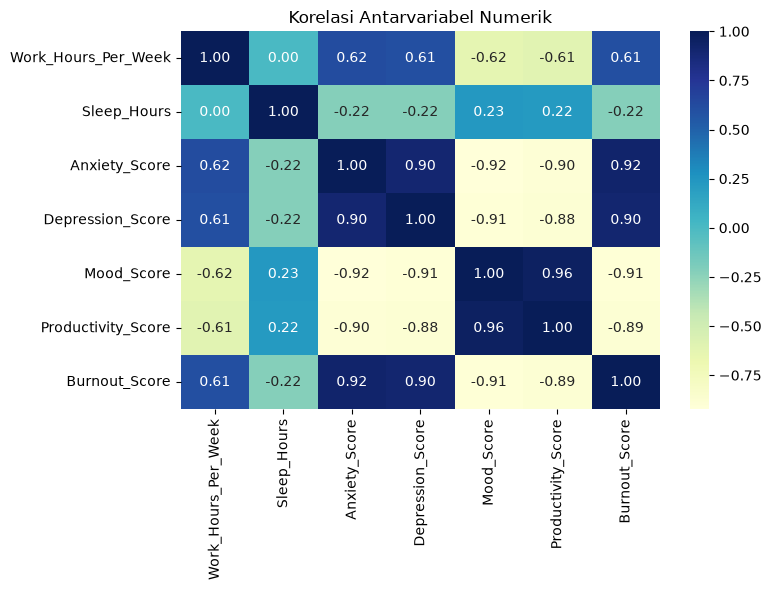

In [6]:
# Korelasi hanya dihitung untuk kolom numerik utama yang relevan.
fitur_korelasi = [
    'Work_Hours_Per_Week', 'Sleep_Hours', 'Anxiety_Score',
    'Depression_Score', 'Mood_Score', 'Productivity_Score', 'Burnout_Score'
]
plt.figure(figsize=(8, 6))
sns.heatmap(data[fitur_korelasi].corr(), cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Korelasi Antarvariabel Numerik')
plt.tight_layout()
plt.show()

Dari bentuk visualisasi di atas terlihat bahwa Anxiety_Score memiliki korelasi positif yang paling kuat terhadap Burnout_Score.

### Regresi Linier

In [7]:
# Pilih variabel bebas berdasarkan hasil analisis korelasi.
X = data['Anxiety_Score']
y = data['Burnout_Score']

X.head()

0    74.0
1    58.0
2    54.0
3    12.0
4    25.0
Name: Anxiety_Score, dtype: float64

In [8]:
# Pisahkan data latih (70%) dan data uji (30%).
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

In [9]:
# Tampilkan ukuran pembagian data dan contoh data latih.
print(f'Data latih: {len(X_train)} baris')
print(f'Data uji: {len(X_test)} baris')
pd.concat([X_train, y_train], axis=1).head()

Data latih: 35000 baris
Data uji: 15000 baris


,Anxiety_Score,Burnout_Score
48824,32.0,42
2704,54.0,53
25631,51.0,53
7285,86.0,65
27346,10.0,0


In [10]:
# training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)

In [11]:
# Latih model regresi linier dengan intercept.
lr = sm.OLS(y_train, X_train_sm).fit()
lr.params

const            2.584024
Anxiety_Score    0.930342
dtype: float64

In [12]:
# analisis statistika dari garis regresi
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          Burnout_Score   R-squared:                       0.840
Model:                            OLS   Adj. R-squared:                  0.840
Method:                 Least Squares   F-statistic:                 1.840e+05
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:14:58   Log-Likelihood:            -1.3189e+05
No. Observations:               35000   AIC:                         2.638e+05
Df Residuals:                   34998   BIC:                         2.638e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             2.5840      0.104     24.834      0.000       2.380       2.788
Anxiety_Score     0.9303      0.002    428.917      0.000       0.926       0.935
==============================================================================
Omnibus:                      166.049   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              212.101
Skew:                           0.081   Prob(JB):                     8.77e-47
Kurtosis:                       3.345   Cond. No.                         89.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

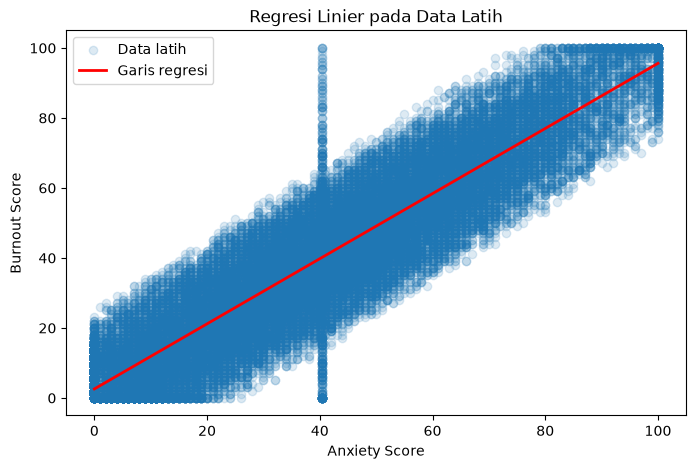

In [13]:
# Gunakan prediksi model, lalu urutkan X agar garis tergambar berurutan.
train_order = np.argsort(X_train.to_numpy())
y_train_line = lr.predict(X_train_sm)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.15, label='Data latih')
plt.plot(
    X_train.iloc[train_order], y_train_line.iloc[train_order],
    color='red', linewidth=2, label='Garis regresi'
)
plt.xlabel('Anxiety Score')
plt.ylabel('Burnout Score')
plt.title('Regresi Linier pada Data Latih')
plt.legend()
plt.show()

### Residual Analysis
dipakai untuk mengetahui tingkat error dari variabel yang dipengaruhi (y)

Error = Actual y value - y predicted value

In [14]:
# prediksi y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

res = (y_train - y_train_pred)

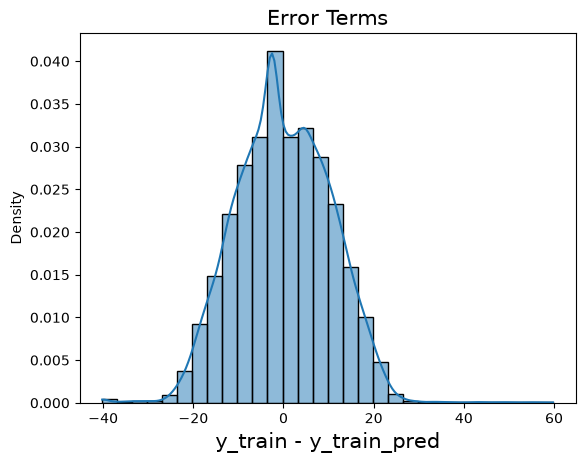

In [15]:
# Histogram dan kurva kepadatan untuk memeriksa distribusi residual.
plt.figure()
sns.histplot(res, bins=30, kde=True, stat='density')
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

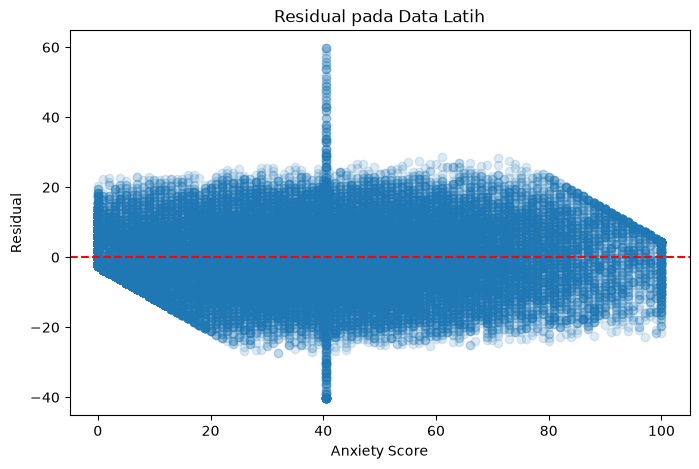

In [16]:
# Periksa pola residual terhadap variabel bebas.
plt.figure(figsize=(8, 5))
plt.scatter(X_train, res, alpha=0.15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Anxiety Score')
plt.ylabel('Residual')
plt.title('Residual pada Data Latih')
plt.show()

In [17]:
# prediksi pada data uji dan evaluasi model
X_test_sm = sm.add_constant(X_test)

# prediksi y value yang berkorelasi dengan X_test_sm
y_test_pred = lr.predict(X_test_sm)

# cetak 5 data terprediksi teratas
y_test_pred.head()

4253     76.081029
30076    26.772912
48047    55.613509
1666     40.728039
30740    47.240432
dtype: float64

In [18]:
# Hitung dan tampilkan R-squared data latih dan data uji.
from sklearn.metrics import r2_score

r_squared_train = r2_score(y_train, y_train_pred)
r_squared = r2_score(y_test, y_test_pred)
print(f'R-squared data latih: {r_squared_train:.4f}')
print(f'R-squared data uji: {r_squared:.4f}')

R-squared data latih: 0.8402
R-squared data uji: 0.8449


Nilai R-squared data latih dan data uji terlihat sangat berdekatan, menunjukkan bahwa model regresi linier sederhana dengan fitur Anxiety_Score mampu menjelaskan sekitar 85% variasi Burnout_Score secara konsisten pada data baru.